# Рекуррентная нейронная сеть (RNN)

Цель — прогноз температуры воздуха на один час вперёд по метеорологическим измерениям за предыдущие 24 часа. Исходный ряд содержит около 420 тыс. десятиминутных измерений; для работы формируются средние часовые значения. Разбиение хронологическое, без случайного перемешивания временных интервалов.

Источник: [Jena Climate / Keras](https://keras.io/examples/timeseries/timeseries_weather_forecasting/).

In [ ]:
%pip install -q numpy pandas matplotlib scipy scikit-learn torch certifi

В первой кодовой ячейке устанавливаются зависимости. Ключ `-q` сокращает служебный вывод pip. При успешной установке ошибок не появляется. PyTorch используется для вычисления градиентов и пакетного обучения.

In [2]:
import os, io, zipfile, gzip, struct, hashlib, math, json
from pathlib import Path
from urllib.request import urlopen, Request
import ssl
import certifi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score, mean_absolute_error,
    mean_squared_error, r2_score)
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import display

Были подключены библиотеки для таблиц, графиков, разделения выборок и расчёта метрик. `torch.nn` содержит слои нейронных сетей, а `DataLoader` выдаёт пакеты примеров. Импорты сами по себе ничего не выводят.

In [3]:
get_ipython().run_line_magic("matplotlib", "inline")
DATA = Path(os.environ.get("ML_DATA_DIR", "data"))
DATA.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))
def seed_all():
    np.random.seed(42)
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)
seed_all()

def fetch(url, name, md5=None):
    path = DATA / name
    def check(file, sha256=None):
        if file.suffix == ".part" and file.stat().st_size == 0:
            raise ValueError("Пустой файл")
        if md5 and hashlib.md5(file.read_bytes()).hexdigest() != md5:
            raise ValueError("Неверная контрольная сумма MD5")
        if sha256 and hashlib.sha256(file.read_bytes()).hexdigest() != sha256:
            raise ValueError("Неверная контрольная сумма SHA-256 резервного архива")
        if name.endswith(".zip"):
            with zipfile.ZipFile(file) as archive:
                if archive.testzip() is not None:
                    raise ValueError("Повреждённый ZIP")
    if path.exists():
        try:
            check(path)
            return path
        except (OSError, ValueError, zipfile.BadZipFile) as exc:
            print(f"Кэш {name} повреждён: {exc}. Повторная загрузка.")
    sources = [(url, None)]
    if name == "bank_marketing.zip":
        # Резервная копия оригинального UCI bank.zip, содержащего bank-full.csv.
        sources.append(("https://raw.githubusercontent.com/raederhans/ca6003-bank-marketing/main/data/source/bank.zip",
                        "99d7e8eb12401ed278b793984423915411ea8df099e1795f9fefe254f513fe5e"))
    tmp = path.with_suffix(path.suffix + ".part")
    errors = []
    for address, sha256 in sources:
        for label, context in [("системные CA", ssl.create_default_context()),
                               ("certifi", ssl.create_default_context(cafile=certifi.where()))]:
            try:
                with urlopen(Request(address, headers={"User-Agent": "Python ML coursework"}),
                             timeout=120, context=context) as response, tmp.open("wb") as out:
                    while chunk := response.read(1024*1024):
                        out.write(chunk)
                check(tmp, sha256)
                tmp.replace(path)
                print(f"Загружен {name}: {address} ({label})")
                return path
            except (OSError, ValueError, zipfile.BadZipFile) as exc:
                tmp.unlink(missing_ok=True)
                errors.append(f"{address} ({label}): {exc}")
                print(errors[-1])
    raise RuntimeError(f"Не удалось безопасно скачать {name}. Проверьте дату Windows, сертификаты и соединение. "
                       f"Можно скачать оригинальный файл вручную и сохранить как {path}.\n" + "\n".join(errors))

def loader(x, y, batch=256, shuffle=False, regression=False):
    a = torch.as_tensor(np.ascontiguousarray(x), dtype=torch.float32)
    b = torch.as_tensor(np.ascontiguousarray(y), dtype=torch.float32 if regression else torch.long)
    return DataLoader(TensorDataset(a,b), batch_size=batch, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(42), num_workers=0)

def evaluate(model, batches, loss_fn, regression=False):
    model.eval(); total=0.; count=0; outputs=[]; targets=[]
    with torch.no_grad():
        for x,y in batches:
            yhat=model(x.to(DEVICE)); y=y.to(DEVICE)
            total += loss_fn(yhat,y).item()*len(y); count += len(y)
            outputs.append(yhat.cpu().numpy()); targets.append(y.cpu().numpy())
    return total/count, np.concatenate(outputs), np.concatenate(targets)

def fit_net(model, train, val, loss_fn, epochs, lr, regression=False):
    model.to(DEVICE); optim=torch.optim.Adam(model.parameters(),lr=lr)
    history=[]; best=float("inf"); best_state=None
    for epoch in range(1,epochs+1):
        model.train(); sum_loss=0.; count=0
        for x,y in train:
            x,y=x.to(DEVICE),y.to(DEVICE)
            optim.zero_grad(); pred=model(x); loss=loss_fn(pred,y)
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),5.0); optim.step()
            sum_loss+=loss.item()*len(y); count+=len(y)
        vloss, vp, vy=evaluate(model,val,loss_fn,regression)
        score=float(np.sqrt(np.mean((vp-vy)**2))) if regression else float(np.mean(vp.argmax(1)==vy))
        history.append((epoch,sum_loss/count,vloss,score))
        if vloss<best:
            best=vloss; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        print(f"Epoch {epoch:02d}: train loss={sum_loss/count:.4f}; val loss={vloss:.4f}; val score={score:.4f}")
    model.load_state_dict(best_state)
    return pd.DataFrame(history,columns=["epoch","train_loss","val_loss","val_score"])

def chart(title,xlabel,ylabel):
    plt.title(title); plt.xlabel(xlabel); plt.ylabel(ylabel); plt.tight_layout(); plt.show(); plt.close()

def heat(a,labels,title,xlabel,ylabel,fmt):
    a=np.asarray(a); plt.figure(figsize=(9,7)); plt.imshow(a,cmap="Blues",aspect="auto"); plt.colorbar()
    plt.xticks(range(len(labels)),labels,rotation=45,ha="right"); plt.yticks(range(len(labels)),labels)
    for i in range(a.shape[0]):
        for j in range(a.shape[1]):
            plt.text(j,i,format(a[i,j],fmt),ha="center",va="center",fontsize=7,
                     color="white" if a[i,j]>a.max()*0.55 else "black")
    chart(title,xlabel,ylabel)

def size_table(train,val,test):
    assert train>=20000, "Training set must contain at least 20,000 examples"
    return {"Train":int(train),"Validation":int(val),"Test":int(test)}

def class_metrics(y,p):
    return {"Accuracy":accuracy_score(y,p),"Macro Precision":precision_score(y,p,average="macro",zero_division=0),
            "Macro Recall":recall_score(y,p,average="macro",zero_division=0),"Macro F1":f1_score(y,p,average="macro",zero_division=0)}
print("Устройство:",DEVICE)

Устройство: cpu


`fetch` сохраняет исходный файл локально, при наличии контрольной суммы проверяет целостность. Для HTTPS используются системные сертификаты или набор `certifi`; проверка сертификатов остаётся включённой. Если основной источник Bank Marketing недоступен, используется копия исходного архива `bank.zip` с проверкой SHA-256. `loader` формирует батчи без копирования примеров между выборками. В `fit_net` последовательно выполняются прямой проход, вычисление функции потерь, `backward()` и обновление весов Adam. Валидация выполняется без градиентов; сохраняется состояние с минимальной ошибкой Validation. Test здесь не используется. `size_table` проверяет наличие не менее 20 000 обучающих примеров. В выводе ячейки указывается выбранное устройство CPU или CUDA.

In [4]:
seed_all()
path=fetch("https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip","jena_climate.zip")
with zipfile.ZipFile(path) as z: df=pd.read_csv(z.open(next(x for x in z.namelist() if x.endswith(".csv"))))
print("Исходный размер:",df.shape); display(df.head()); df.info()
cols=["T (degC)","p (mbar)","rh (%)","wv (m/s)","Tdew (degC)"]
dates=pd.to_datetime(df["Date Time"],format="%d.%m.%Y %H:%M:%S",errors="coerce")
v=df[cols].apply(pd.to_numeric,errors="coerce"); v.index=dates
print("Пропуски:"); display(v.isna().sum()); print("Дубликаты времени:",int(v.index.duplicated().sum()))
print("Некорректные даты:",int(v.index.isna().sum()))
print("Описательная статистика:"); display(v.describe().T)
valid=(v["T (degC)"].between(-60,60)&v["p (mbar)"].between(800,1100)&v["rh (%)"].between(0,100)&v["wv (m/s)"].between(0,100)&v["Tdew (degC)"].between(-80,60))
print("Некорректные значения:",int((~valid).sum()))
v.loc[~valid.to_numpy(),:]=np.nan
v=v.loc[~v.index.isna()].sort_index(); v=v.loc[~v.index.duplicated(keep="first")]
hour=v.resample("1h").mean(); count=v.resample("1h").count().min(axis=1); hour.loc[count<3]=np.nan
print("Часов:",len(hour),"Неполных часов:",int(hour.isna().any(axis=1).sum()))

Загружен jena_climate.zip: https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip (системные CA)


Исходный размер: (420551, 15)


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420551 entries, 0 to 420550
Data columns (total 15 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Date Time        420551 non-null  object 
 1   p (mbar)         420551 non-null  float64
 2   T (degC)         420551 non-null  float64
 3   Tpot (K)         420551 non-null  float64
 4   Tdew (degC)      420551 non-null  float64
 5   rh (%)           420551 non-null  float64
 6   VPmax (mbar)     420551 non-null  float64
 7   VPact (mbar)     420551 non-null  float64
 8   VPdef (mbar)     420551 non-null  float64
 9   sh (g/kg)        420551 non-null  float64
 10  H2OC (mmol/mol)  420551 non-null  float64
 11  rho (g/m**3)     420551 non-null  float64
 12  wv (m/s)         420551 non-null  float64
 13  max. wv (m/s)    420551 non-null  float64
 14  wd (deg)         420551 non-null  float64
dtypes: float64(14), object(1)
memory usage: 48.1+ MB


Пропуски:


T (degC)       0
p (mbar)       0
rh (%)         0
wv (m/s)       0
Tdew (degC)    0
dtype: int64

Дубликаты времени: 327
Некорректные даты: 0
Описательная статистика:


,count,mean,std,min,25%,50%,75%,max
T (degC),420551.0,9.450147,8.423365,-23.01,3.36,9.42,15.47,37.28
p (mbar),420551.0,989.212776,8.358481,913.60,984.20,989.58,994.72,1015.35
rh (%),420551.0,76.008259,16.476175,12.95,65.21,79.30,89.40,100.00
wv (m/s),420551.0,1.702224,65.446714,-9999.00,0.99,1.76,2.86,28.49
Tdew (degC),420551.0,4.955854,6.730674,-25.01,0.24,5.22,10.07,23.11


Некорректные значения: 18


Часов: 70129 Неполных часов: 94


В CSV проверены метки времени, повторения, пропуски и физически допустимые диапазоны пяти выбранных величин; служебные значения вроде отрицательной скорости ветра исключаются. `resample("1h").mean()` усредняет измерения за час. Если наблюдений меньше трёх, час считается неполным. Неполные часы не интерполируются будущими значениями. В выводе приведены формы, статистика и число исключённых наблюдений.

In [5]:
n=len(hour); t1=int(n*.70); t2=int(n*.85)
blocks=[hour.iloc[:t1],hour.iloc[t1:t2],hour.iloc[t2:]]
scaler=StandardScaler().fit(blocks[0].dropna())
def windows(block):
    x=scaler.transform(block).astype(np.float32); steps=24
    w=np.lib.stride_tricks.sliding_window_view(x,steps+1,axis=0).transpose(0,2,1)
    mask=np.isfinite(w).all(axis=(1,2)); w=w[mask]
    return w[:,:steps].copy(),w[:,steps,0:1].copy(),block.index[steps:][mask]
a,ya,ta=windows(blocks[0]); b,yb,tb=windows(blocks[1]); c,yc,tc=windows(blocks[2])
sizes=size_table(len(a),len(b),len(c)); print(sizes); print("Форма Train:",a.shape,ya.shape)
print("Границы:",ta[0],ta[-1],tb[0],tb[-1],tc[0],tc[-1])
eda=blocks[0].dropna(); cal=blocks[0]["T (degC)"]
q1,q3=eda.quantile(.25),eda.quantile(.75); iqr=q3-q1; display(((eda<q1-1.5*iqr)|(eda>q3+1.5*iqr)).sum().to_frame("IQR"))

{'Train': 49066, 'Validation': 10428, 'Test': 10397}
Форма Train: (49066, 24, 5) (49066, 1)
Границы: 2009-01-02 00:00:00 2014-08-08 09:00:00 2014-08-09 10:00:00 2015-10-20 16:00:00 2015-10-21 17:00:00 2016-12-31 23:00:00


,IQR
T (degC),174
p (mbar),772
rh (%),78
wv (m/s),1616
Tdew (degC),371


Сначала данные разделены по времени в пропорции 70/15/15, затем StandardScaler обучен исключительно на полных часах Train. `sliding_window_view` создаёт окна из 25 часов: первые 24 — вход, 25-й — целевая температура. Окна с пропусками исключены, границы выборок не пересекаются. Печатаются размеры и диапазоны дат, а IQR-таблица показывает потенциальные крайние значения Train; редкие погодные значения не удаляются автоматически. Окна внутри выборки перекрываются, поэтому это не независимые наблюдения.

### График временного ряда

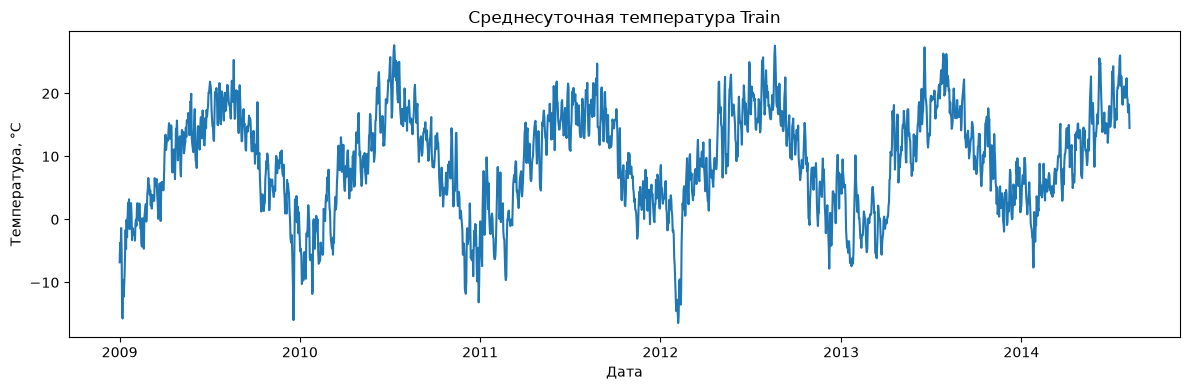

In [6]:
plt.figure(figsize=(12,4)); plt.plot(cal.resample("1D").mean()); chart("Среднесуточная температура Train", "Дата", "Температура, °C")

Линия показывает среднюю температуру каждого дня обучающего периода. Повторение подъёмов и спадов отражает годовую сезонность. Дневное усреднение применяется только для визуализации.

### Гистограмма температуры

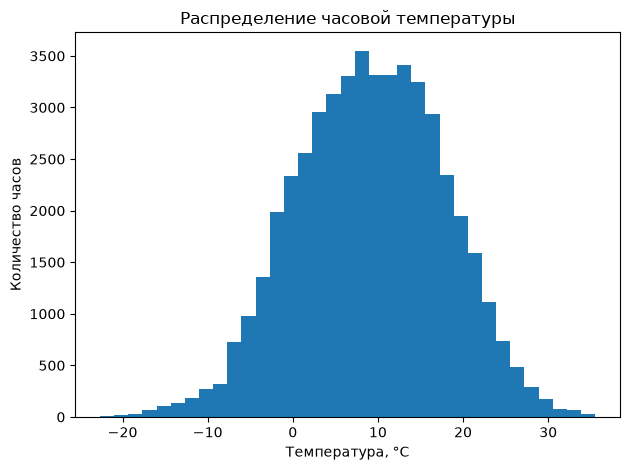

In [7]:
plt.figure(); plt.hist(eda["T (degC)"],bins=35); chart("Распределение часовой температуры", "Температура, °C", "Количество часов")

Высота столбца — число часов в заданном диапазоне температуры. По форме распределения судят о частых значениях и редких экстремумах.

### Диаграмма размаха по месяцам

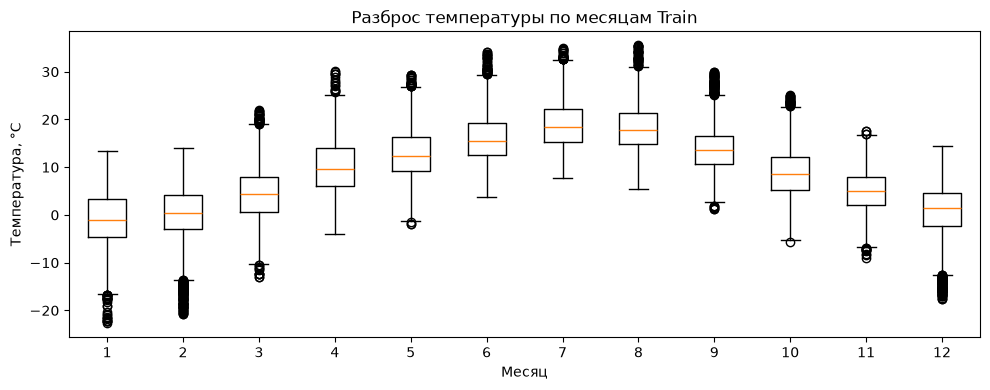

In [8]:
plt.figure(figsize=(10,4)); plt.boxplot([eda.loc[eda.index.month==k,"T (degC)"] for k in range(1,13)],tick_labels=list(range(1,13))); chart("Разброс температуры по месяцам Train", "Месяц", "Температура, °C")

Каждая коробка характеризует центральные 50% температур данного месяца, центральная линия — медиана. Усы и точки отображают разброс температур; различие медиан характеризует сезонность.

### Суточный профиль

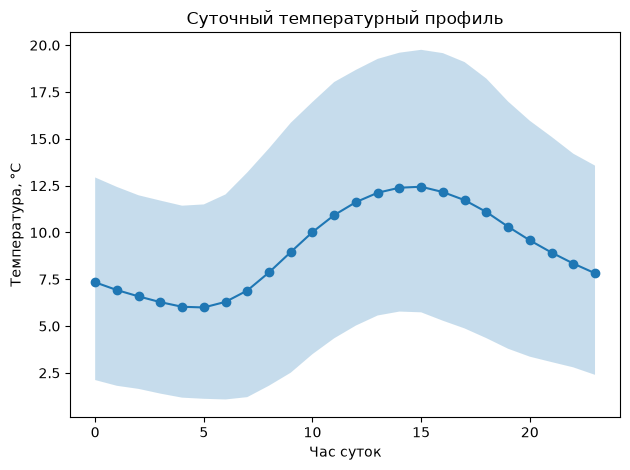

In [9]:
g=eda["T (degC)"].groupby(eda.index.hour); plt.figure(); plt.plot(g.mean(),marker="o"); plt.fill_between(np.arange(24),g.quantile(.25).values,g.quantile(.75).values,alpha=.25); chart("Суточный температурный профиль", "Час суток", "Температура, °C")

Линия соответствует средней температуре в каждый час суток, полоса — межквартильный диапазон. Часть изменения связана с суточным циклом; ширина полосы отражает сезонный и погодный разброс.

### Автокорреляционная функция

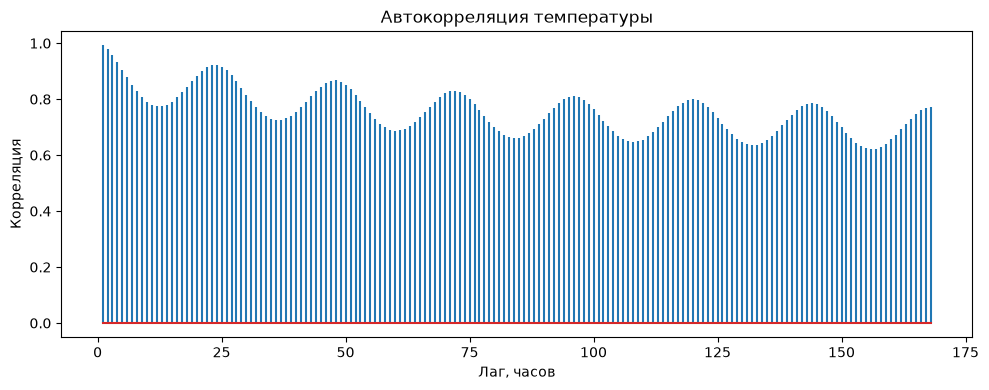

In [10]:
plt.figure(figsize=(10,4)); lags=np.arange(1,169); ac=[cal.autocorr(int(k)) for k in lags]; plt.stem(lags,ac,markerfmt=" "); chart("Автокорреляция температуры", "Лаг, часов", "Корреляция")

Для каждой задержки рассчитывается корреляция ряда с собственной сдвинутой копией. Пики на кратных 24 часам могут указывать на суточную периодичность. Используется только Train; пропуски учитываются попарно.

### Корреляционная матрица

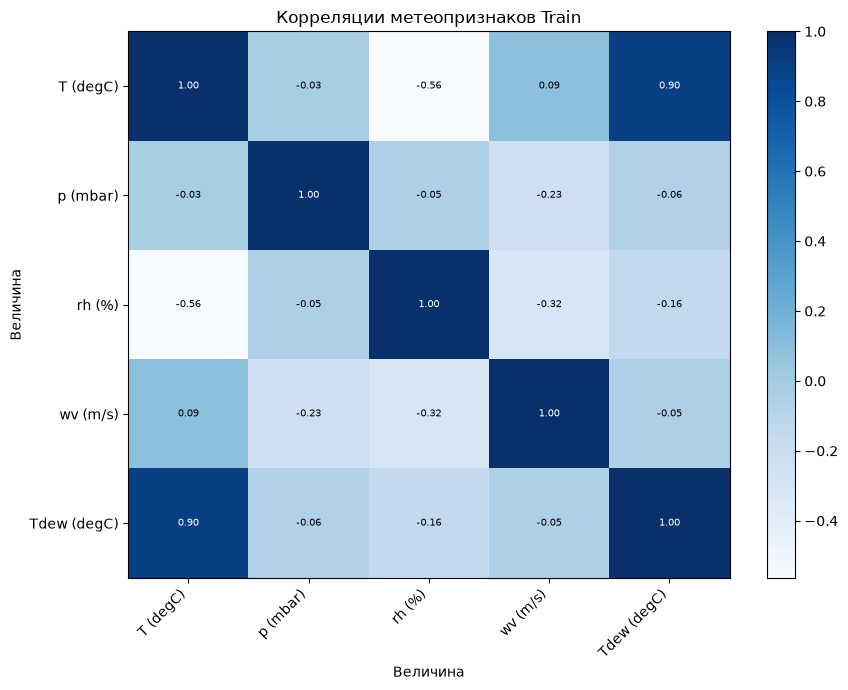

In [11]:
corr=eda.corr(); heat(corr,corr.columns,"Корреляции метеопризнаков Train", "Величина", "Величина", ".2f")

Ячейки показывают коэффициенты Пирсона между пятью погодными величинами. Корреляция описывает линейную связь, но не причинность. Сильная связь температуры и точки росы физически закономерна.

In [12]:
train=loader(a,ya,batch=256,shuffle=True,regression=True); val=loader(b,yb,regression=True); test=loader(c,yc,regression=True)
class WeatherRNN(nn.Module):
    def __init__(self):
        super().__init__(); self.rnn=nn.RNN(input_size=5,hidden_size=32,batch_first=True); self.out=nn.Linear(32,1)
    def forward(self,x):
        _,h=self.rnn(x); return self.out(h[-1])
model=WeatherRNN(); loss_fn=nn.MSELoss(); print(model); print("Параметров:",sum(p.numel() for p in model.parameters()))
history=fit_net(model,train,val,loss_fn,epochs=20,lr=.001,regression=True)
_,p,y=evaluate(model,test,loss_fn,regression=True)
true=y.ravel()*scaler.scale_[0]+scaler.mean_[0]; pred=p.ravel()*scaler.scale_[0]+scaler.mean_[0]
baseline=c[:,-1,0]*scaler.scale_[0]+scaler.mean_[0]
err=true-pred
m={"MAE (°C)":mean_absolute_error(true,pred),"RMSE (°C)":float(np.sqrt(mean_squared_error(true,pred))),"R2":r2_score(true,pred),"Baseline MAE (°C)":mean_absolute_error(true,baseline),"Baseline RMSE (°C)":float(np.sqrt(mean_squared_error(true,baseline)))}
print(m); display(pd.DataFrame({"Дата":tc,"Факт":true,"Прогноз":pred,"Остаток":err}).head(10))

WeatherRNN(
  (rnn): RNN(5, 32, batch_first=True)
  (out): Linear(in_features=32, out_features=1, bias=True)
)
Параметров: 1281


Epoch 01: train loss=0.1499; val loss=0.0236; val score=0.1537


Epoch 02: train loss=0.0173; val loss=0.0147; val score=0.1214


Epoch 03: train loss=0.0121; val loss=0.0112; val score=0.1058


Epoch 04: train loss=0.0096; val loss=0.0094; val score=0.0969


Epoch 05: train loss=0.0081; val loss=0.0080; val score=0.0897


... (12 outputs left out)

Epoch 18: train loss=0.0047; val loss=0.0049; val score=0.0701


Epoch 19: train loss=0.0048; val loss=0.0049; val score=0.0698


Epoch 20: train loss=0.0047; val loss=0.0048; val score=0.0695
{'MAE (°C)': 0.3929218305195553, 'RMSE (°C)': 0.5615763014447517, 'R2': 0.994831419646197, 'Baseline MAE (°C)': 0.6474964704250137, 'Baseline RMSE (°C)': 0.9048572345291271}


,Дата,Факт,Прогноз,Остаток
0,2015-10-21 17:00:00,8.990000,9.099606,-0.109606
1,2015-10-21 18:00:00,8.568333,8.599665,-0.031332
2,2015-10-21 19:00:00,8.083333,8.289902,-0.206569
3,2015-10-21 20:00:00,7.691667,7.748944,-0.057277
4,2015-10-21 21:00:00,6.891667,7.375094,-0.483427
5,2015-10-21 22:00:00,6.256667,6.193341,0.063326
6,2015-10-21 23:00:00,5.671667,5.837045,-0.165378
7,2015-10-22 00:00:00,5.365000,5.328771,0.036229
8,2015-10-22 01:00:00,4.940000,5.267944,-0.327944
9,2015-10-22 02:00:00,4.471667,4.703216,-0.231549


`nn.RNN` последовательно обрабатывает 24 временных шага, обновляя скрытое состояние из 32 нейронов. Последнее состояние `h[-1]` поступает в линейный выход. Батчи окон перемешиваются только внутри Train, порядок часов внутри окна остаётся прежним. MSE применяется к стандартизированной температуре; после обучения прогноз возвращён в °C. MAE показывает средний модуль ошибки, RMSE сильнее реагирует на крупные ошибки, R² сравнивает результат с постоянным прогнозом среднего Test. Baseline — последнее известное значение температуры. Вывод содержит архитектуру, историю обучения, метрики и первые десять фактических/предсказанных значений.

### Кривые функции потерь

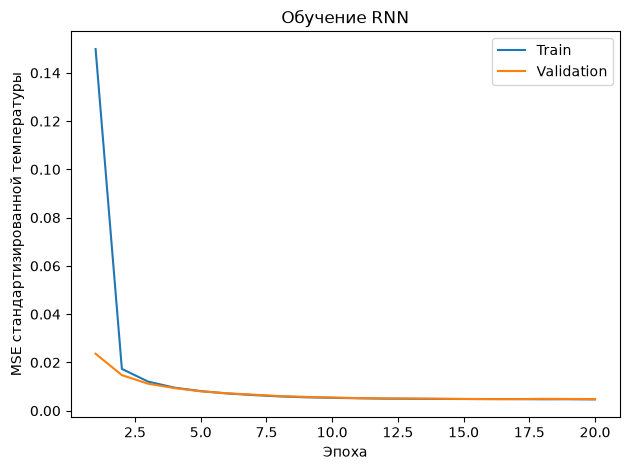

In [13]:
plt.figure(); plt.plot(history.epoch,history.train_loss,label="Train"); plt.plot(history.epoch,history.val_loss,label="Validation"); plt.legend(); chart("Обучение RNN", "Эпоха", "MSE стандартизированной температуры")

Кривые ошибки показывают, как меняется качество в процессе обучения. Выбор состояния сети производится по минимуму Validation MSE; Test не используется при подборе весов.

### Сопоставление прогнозов с фактом

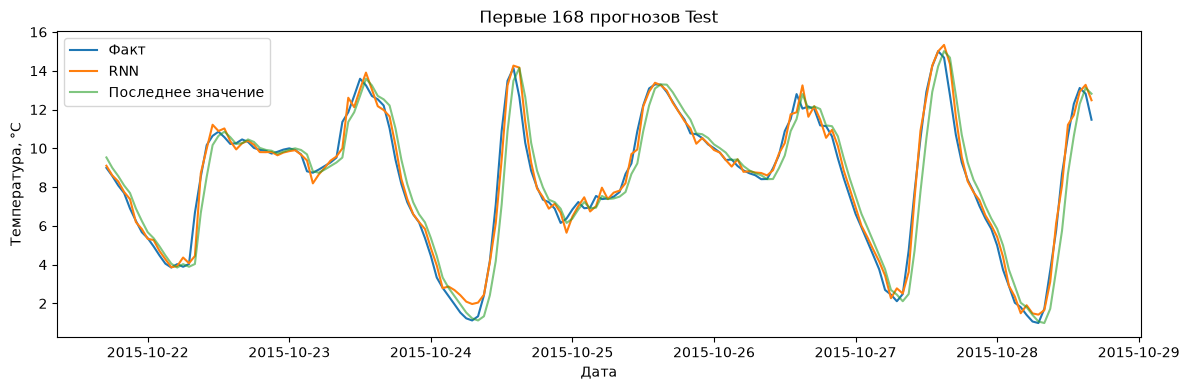

In [14]:
plt.figure(figsize=(12,4)); k=min(168,len(tc)); plt.plot(tc[:k],true[:k],label="Факт"); plt.plot(tc[:k],pred[:k],label="RNN"); plt.plot(tc[:k],baseline[:k],label="Последнее значение",alpha=.6); plt.legend(); chart("Первые 168 прогнозов Test", "Дата", "Температура, °C")

На графике показан начальный участок тестовых прогнозов. Совпадение линий отражает точность, а заметный сдвиг может указывать на запаздывание. Базовый прогноз позволяет оценить вклад сети по сравнению с простым правилом.

### Диаграмма фактических и предсказанных значений

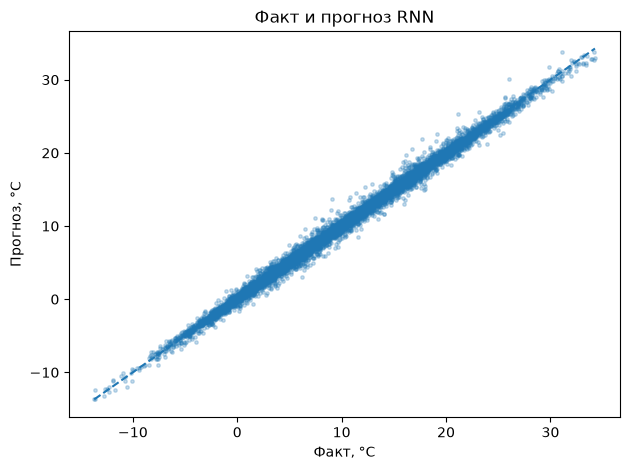

In [15]:
plt.figure(); plt.scatter(true,pred,s=6,alpha=.25); lo=min(true.min(),pred.min()); hi=max(true.max(),pred.max()); plt.plot([lo,hi],[lo,hi],"--"); chart("Факт и прогноз RNN", "Факт, °C", "Прогноз, °C")

Каждая точка соответствует тестовому окну. Диагональ означает идеальное совпадение. Чем ближе облако к диагонали, тем меньше ошибка; отклонения выявляют систематические промахи при отдельных температурах.

### Гистограмма остатков

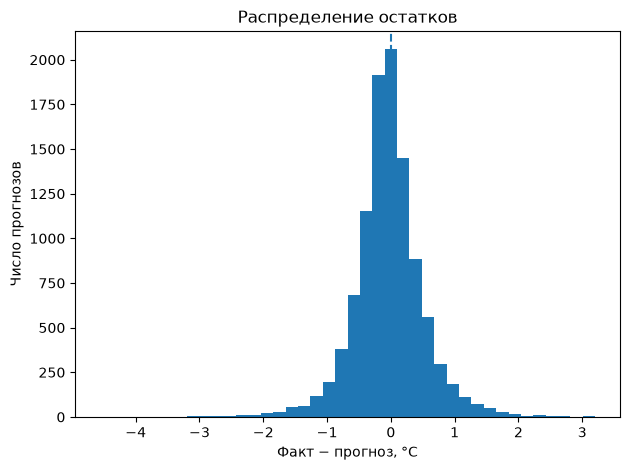

In [16]:
plt.figure(); plt.hist(err,bins=40); plt.axvline(0,ls="--"); chart("Распределение остатков", "Факт − прогноз, °C", "Число прогнозов")

Положительный остаток означает занижение прогноза, отрицательный — завышение. Концентрация около нуля и симметрия дают представление о систематической ошибке; длинные хвосты показывают крупные промахи.

### Диаграмма остатков

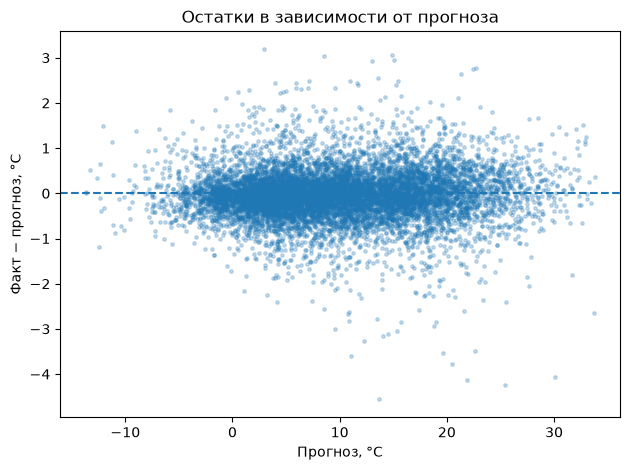

In [17]:
plt.figure(); plt.scatter(pred,err,s=6,alpha=.25); plt.axhline(0,ls="--"); chart("Остатки в зависимости от прогноза", "Прогноз, °C", "Факт − прогноз, °C")

По X — рассчитанная температура, по Y — подписанная ошибка. Желательно отсутствие выраженной зависимости остатков от уровня прогноза. Изгиб или расширение облака может означать систематическую проблему модели.

### Сравнение ошибок с базовой моделью

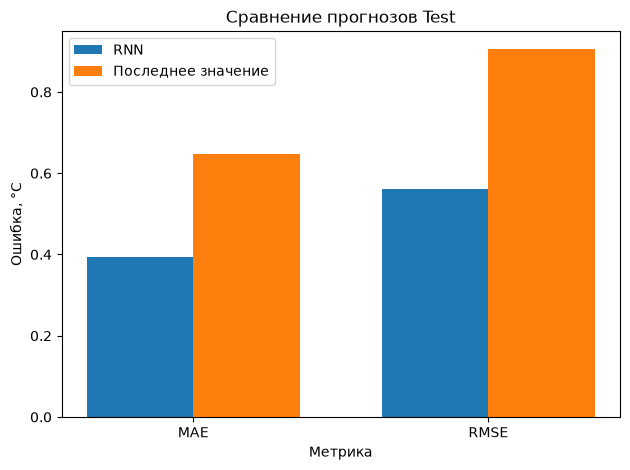

In [18]:
plt.figure(); names=["MAE","RMSE"]; pos=np.arange(2); plt.bar(pos-.18,[m["MAE (°C)"],m["RMSE (°C)"]],.36,label="RNN"); plt.bar(pos+.18,[m["Baseline MAE (°C)"],m["Baseline RMSE (°C)"]],.36,label="Последнее значение"); plt.xticks(pos,names); plt.legend(); chart("Сравнение прогнозов Test", "Метрика", "Ошибка, °C")

Сравниваются MAE и RMSE сети и базового прогноза на одних и тех же Test-окнах. Меньшая высота означает меньшую ошибку. Если RNN не выигрывает у базового метода, это ограничение необходимо отразить в выводе.

In [19]:
REPORT = {"sizes": sizes, "metrics": m, "conclusion": f"Для обучения сформировано {sizes['Train']} временных окон (они перекрываются внутри Train). MAE={m['MAE (°C)']:.3f} °C, RMSE={m['RMSE (°C)']:.3f} °C, R²={m['R2']:.3f}. Базовый MAE={m['Baseline MAE (°C)']:.3f} °C; " + ("по MAE сеть превосходит базовый прогноз." if m["MAE (°C)"]<m["Baseline MAE (°C)"] else "по MAE преимущество над базовым прогнозом не получено.")}
print(REPORT["conclusion"])

Для обучения сформировано 49066 временных окон (они перекрываются внутри Train). MAE=0.393 °C, RMSE=0.562 °C, R²=0.995. Базовый MAE=0.647 °C; по MAE сеть превосходит базовый прогноз.


В итоговой строке выводится вывод по фактическим размерам обучающей выборки и метрикам Test.